# Objectifs d'apprentissage – Semaine 10

À l'issue de cette semaine, l'étudiant sera capable de :

- **Comprendre** les différentes structures d'implémentation des filtres RIF et RII.
- **Implémenter** un filtre RIF sous forme directe et en cascade.
- **Implémenter** un filtre RII sous forme directe I, directe II, cascade et parallèle.
- **Analyser** l'influence de la structure sur les performances (stabilité, bruit de calcul).
- **Évaluer** le retard de groupe et la phase d'un filtre.
- **Simuler** les effets de la quantification en virgule fixe sur un filtre numérique.
- **Comparer** les filtres RIF et RII en termes de complexité, phase et stabilité.
- **Utiliser** Python pour l'implémentation et l'analyse de filtres numériques.

# 1. Rappels théoriques

## 1.1 Structures pour les filtres RIF

Un filtre RIF (FIR) est défini par l'équation aux différences :
$$ y[n] = \sum_{k=0}^{M} b_k \, x[n-k] $$

### Structure directe (transversale)
C'est l'implémentation directe de la convolution. Elle est simple et stable, mais peut nécessiter beaucoup de multiplications si l'ordre est élevé.

### Structure en cascade
On factorise la fonction de transfert en sections du second ordre (SOS) :
$$ H(z) = \prod_{k} H_k(z) $$
avec $H_k(z) = b_{0k} + b_{1k} z^{-1} + b_{2k} z^{-2}$.
Cela permet de réduire les effets de quantification et d'implémenter des filtres de grande longueur.

### Structure pour phase linéaire
Si les coefficients sont symétriques, on peut réduire le nombre de multiplications par 2.

## 1.2 Structures pour les filtres RII

Un filtre RII (IIR) est défini par :
$$ \sum_{k=0}^{N} a_k \, y[n-k] = \sum_{k=0}^{M} b_k \, x[n-k] $$
avec $a_0 = 1$.

### Forme directe I
Sépare les parties feedforward (numérateur) et feedback (dénominateur).

### Forme directe II
Réduction du nombre de registres en partageant les retards. Plus économe en mémoire.

### Forme en cascade
Factorisation en sections du second ordre (biquad) : $H(z) = \prod H_k(z)$.
Chaque section est stable si ses pôles sont à l'intérieur du cercle unité.
Cette structure minimise les effets de la quantification et est la plus utilisée en pratique.

### Forme parallèle
Décomposition en fractions partielles : $H(z) = K + \sum \frac{r_k}{1 - p_k z^{-1}}$.
Utilisée parfois pour des filtres à pôles réels.

## 1.3 Retard de groupe
Le retard de groupe $\tau_g(\omega)$ est défini par :
$$ \tau_g(\omega) = -\frac{d}{d\omega} \arg H(e^{j\omega}) $$
Il mesure la distorsion de phase. Pour un filtre à phase linéaire, $\tau_g$ est constant.

## 1.4 Effets de la quantification
En implémentation réelle (processeur DSP, FPGA), les coefficients et les calculs sont quantifiés. Cela peut entraîner :
- Erreurs de troncature/arrondi.
- Bruit de quantification en sortie.
- Oscillations (limit cycles) pour les filtres RII.

---

# 2. Démonstrations Python

## 2.1 Implémentation d'un filtre RIF – Structure directe

Nous allons implémenter un filtre RIF passe-bas en utilisant la convolution directe et comparer avec `lfilter`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import fft, fftfreq

print("Bibliothèques chargées.")

Bibliothèques chargées.


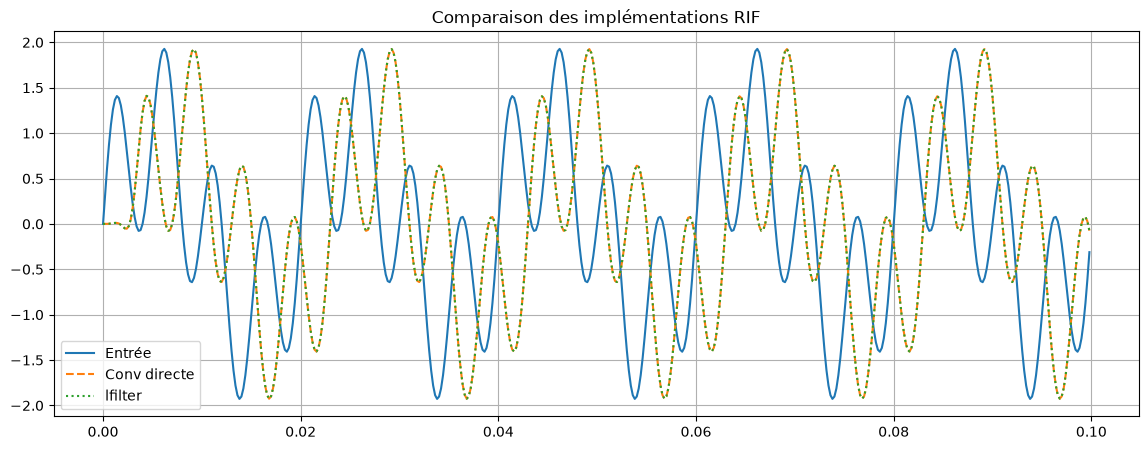

Erreur max entre les deux : 0.0


In [2]:
# Conception d'un filtre RIF passe-bas
fs = 1000
fc = 100
N = 31  # ordre 30
b = signal.firwin(N, fc, fs=fs, window='hamming')

# Implémentation directe par convolution
def fir_filter(x, b):
    y = np.convolve(x, b, mode='full')
    return y[:len(x)]  # on tronque pour garder la même longueur

# Signal test
t = np.linspace(0, 0.1, 500, endpoint=False)
x = np.sin(2*np.pi*50*t) + np.sin(2*np.pi*200*t)

y_conv = fir_filter(x, b)
y_lfilter = signal.lfilter(b, 1, x)

plt.figure(figsize=(14, 5))
plt.plot(t, x, label='Entrée')
plt.plot(t, y_conv, '--', label='Conv directe')
plt.plot(t, y_lfilter, ':', label='lfilter')
plt.legend()
plt.grid()
plt.title('Comparaison des implémentations RIF')
plt.show()
print("Erreur max entre les deux :", np.max(np.abs(y_conv - y_lfilter)))

## 2.2 Structure en cascade pour RIF

Décomposons un filtre RIF en sections du second ordre.

c:\Users\RAWAA\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\scipy\signal\_filter_design.py:1234: BadCoefficients: Badly conditioned filter coefficients (numerator): the results may be meaningless
  b, a = normalize(b, a)


Nombre de sections : 15
[[ 1.20142638e-03 -3.50782491e-03  2.66704843e-03  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00 -7.60763806e-01  1.13993205e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00 -4.45897340e-01  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00  1.90247028e+00  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00  1.17819278e+00  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00  1.48805025e+00  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00  8.16718191e-01  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00  4.18723996e-01  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00 -1.09876196e+00  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00 -9.65981738e-04  1.00000000e+00  1.00000000e+00
 

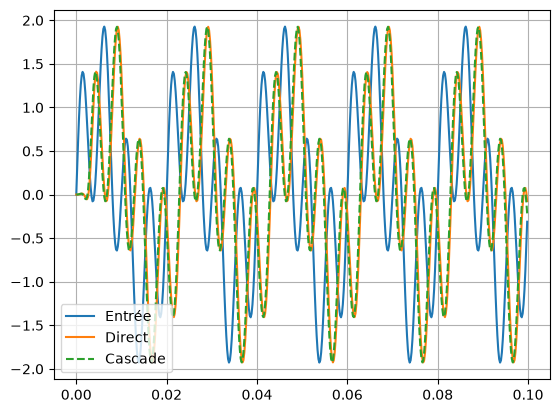

Erreur max : 0.3110169989336258


In [3]:
# Utilisation de scipy.signal.tf2sos pour obtenir les sections
sos = signal.tf2sos(b, 1)
print(f"Nombre de sections : {len(sos)}")
print(sos)

# Implémentation en cascade
def fir_sos_filter(x, sos):
    y = x.copy()
    for section in sos:
        b_section = section[:3]
        # a_section = section[3:]  # pour RIF, a = [1, 0, 0] car section purement feedforward
        y = signal.lfilter(b_section, [1], y)
    return y

y_cascade = fir_sos_filter(x, sos)

plt.plot(t, x, label='Entrée')
plt.plot(t, y_lfilter, label='Direct')
plt.plot(t, y_cascade, '--', label='Cascade')
plt.legend()
plt.grid()
plt.show()
print("Erreur max :", np.max(np.abs(y_lfilter - y_cascade)))

## 2.3 Structures pour les filtres RII

Nous allons concevoir un filtre RII (Butterworth) et l'implémenter dans différentes structures.

Nombre de sections : 2


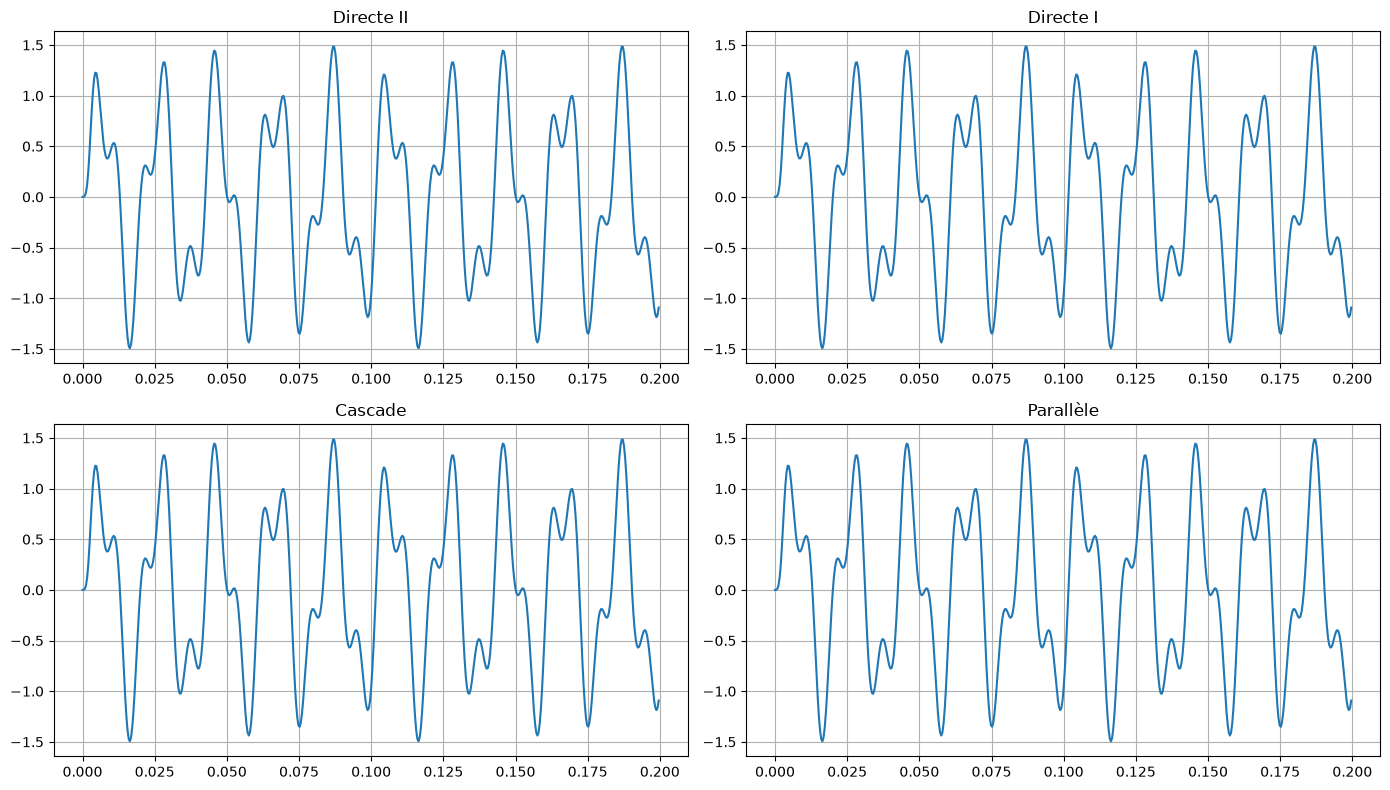

Erreur max Directe I vs Directe II: 5.773159728050814e-15
Erreur max Cascade vs Directe II: 6.661338147750939e-15
Erreur max Parallèle vs Directe II: 1.5765166949677223e-14


In [24]:
# Conception d'un filtre RII passe-bas Butterworth ordre 4
order = 4
b, a = signal.butter(order, fc, fs=fs, btype='low')

# Forme directe II (via lfilter déjà)
y_direct2 = signal.lfilter(b, a, x)

# Forme directe I (implémentation manuelle)
def iir_direct1(x, b, a):
    # On suppose a[0]=1
    N = len(x)
    M = len(b) - 1
    N_a = len(a) - 1
    y = np.zeros(N)
    x_buf = np.zeros(M+1)
    y_buf = np.zeros(N_a+1)
    for n in range(N):
        # Mise à jour des buffers
        x_buf[1:] = x_buf[:-1]
        x_buf[0] = x[n]
        y_buf[1:] = y_buf[:-1]
        # Calcul
        y[n] = np.dot(b, x_buf) - np.dot(a[1:], y_buf[1:])
        y_buf[0] = y[n]
    return y

y_direct1 = iir_direct1(x, b, a)

# Forme en cascade (sections biquad)
sos_iir = signal.tf2sos(b, a)
print(f"Nombre de sections : {len(sos_iir)}")
def iir_sos_filter(x, sos):
    y = x.copy()
    for section in sos:
        b_section = section[:3]
        a_section = section[3:]
        y = signal.lfilter(b_section, a_section, y)
    return y

y_sos = iir_sos_filter(x, sos_iir)

# Forme parallèle (décomposition en fractions partielles)
r, p, k = signal.residuez(b, a)
def iir_parallel(x, r, p, k):
    y = np.zeros_like(x)
    y = np.zeros(len(x), dtype=complex)
    # Terme direct
    if len(k) > 0:
        y += k[0] * x
    # Chaque fraction
    for ri, pi in zip(r, p):
        # H(z) = ri / (1 - pi z^{-1})
        # Implémentation récursive du premier ordre
        b_sec = [ri]
        a_sec = [1, -pi]
        y += signal.lfilter(b_sec, a_sec, x)
    return np.real_if_close(y)

y_parallel = iir_parallel(x, r, p, k)

# Comparaison
plt.figure(figsize=(14, 8))
plt.subplot(2, 2, 1)
plt.plot(t, y_direct2, label='Directe II')
plt.title('Directe II')
plt.grid()
plt.subplot(2, 2, 2)
plt.plot(t, y_direct1, label='Directe I')
plt.title('Directe I')
plt.grid()
plt.subplot(2, 2, 3)
plt.plot(t, y_sos, label='Cascade')
plt.title('Cascade')
plt.grid()
plt.subplot(2, 2, 4)
plt.plot(t, y_parallel, label='Parallèle')
plt.title('Parallèle')
plt.grid()
plt.tight_layout()
plt.show()

# Vérification de l'erreur
print("Erreur max Directe I vs Directe II:", np.max(np.abs(y_direct1 - y_direct2)))
print("Erreur max Cascade vs Directe II:", np.max(np.abs(y_sos - y_direct2)))
print("Erreur max Parallèle vs Directe II:", np.max(np.abs(y_parallel - y_direct2)))

## 2.4 Analyse du retard de groupe

Calculons le retard de groupe pour un filtre RIF (phase linéaire) et un filtre RII.

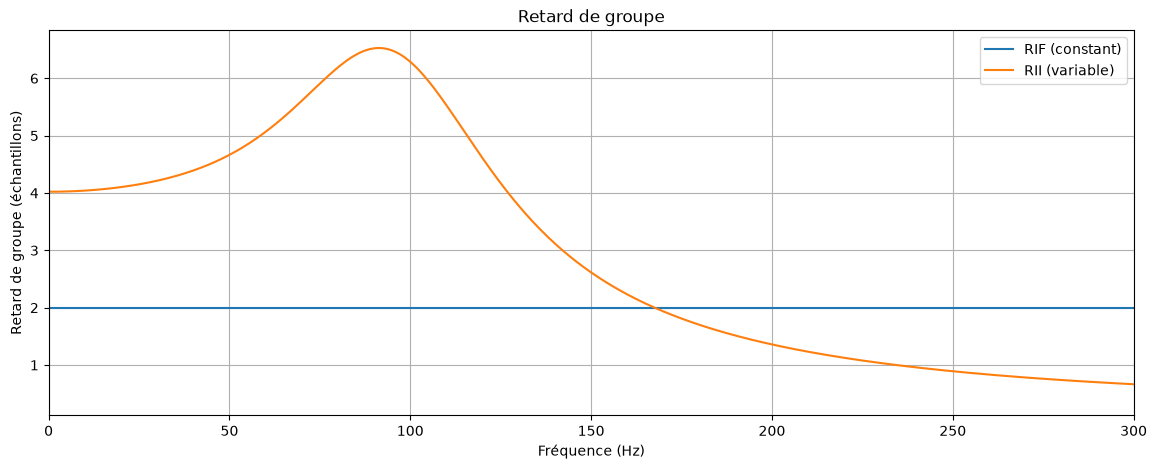

Retard de groupe du RIF : 2.00 échantillons


In [28]:
from scipy.signal import group_delay

# RIF
w, gd_fir = group_delay((b, 1), w=1024)

# RII
w, gd_iir = group_delay((b, a), w=1024)

# Conversion en Hz
freqs = w * fs / (2*np.pi)

plt.figure(figsize=(14, 5))
plt.plot(freqs, gd_fir, label='RIF (constant)')
plt.plot(freqs, gd_iir, label='RII (variable)')

plt.xlabel('Fréquence (Hz)')
plt.ylabel('Retard de groupe (échantillons)')
plt.xlim(0, 300)
plt.legend()
plt.grid()
plt.title('Retard de groupe')
plt.show()

print(f"Retard de groupe du RIF : {gd_fir[0]:.2f} échantillons")

## 2.5 Simulation des effets de quantification

Simulons un filtre RII en virgule fixe (représentation Q15) pour observer l'impact sur la réponse.

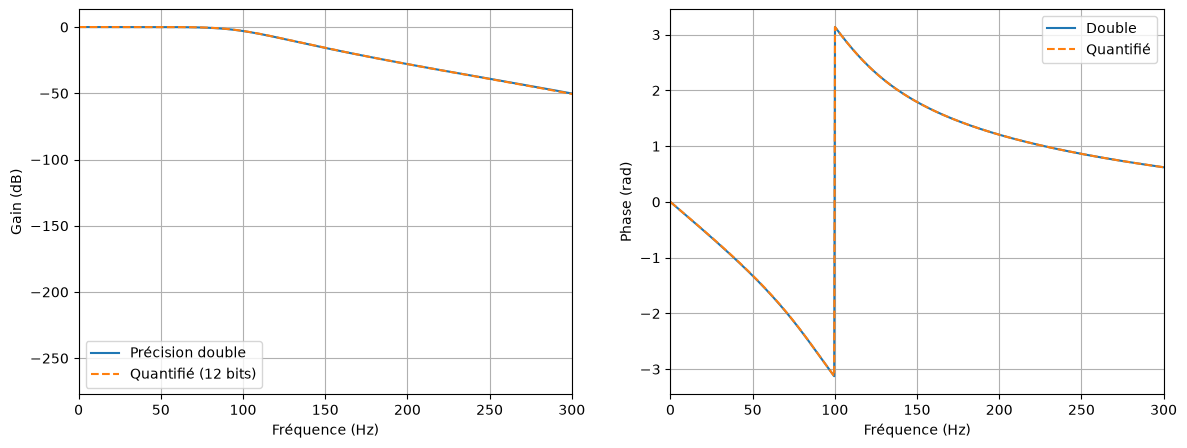

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


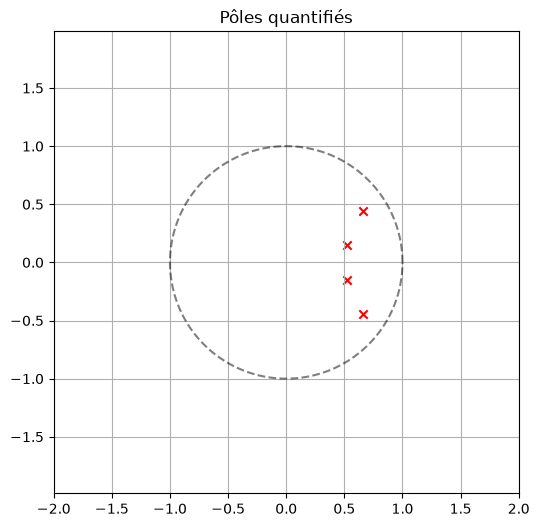

Filtre quantifié stable : True


In [19]:
def quantize_coeffs(coeffs, n_bits=16, scale=1.0):
    """Quantifie des coefficients sur n_bits avec mise à l'échelle."""
    # Qn format : valeurs entre -1 et 1 représentées sur n_bits
    max_val = 2**(n_bits-1) - 1
    coeffs_scaled = coeffs * scale
    coeffs_int = np.round(coeffs_scaled * max_val)
    coeffs_q = coeffs_int / max_val
    return coeffs_q / scale  # remettre à l'échelle

# Quantification des coefficients du RII
b_q = quantize_coeffs(b, n_bits=12)
a_q = quantize_coeffs(a, n_bits=12)

# Réponses fréquentielles
w, H = signal.freqz(b, a, worN=1024)
w, H_q = signal.freqz(b_q, a_q, worN=1024)

freqs = w * fs / (2*np.pi)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(freqs, 20*np.log10(np.abs(H)), label='Précision double')
plt.plot(freqs, 20*np.log10(np.abs(H_q)), '--', label='Quantifié (12 bits)')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Gain (dB)')
plt.xlim(0, 300)
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(freqs, np.angle(H), label='Double')
plt.plot(freqs, np.angle(H_q), '--', label='Quantifié')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Phase (rad)')
plt.xlim(0, 300)
plt.legend()
plt.grid()
plt.show()

# Pôles quantifiés
zeros, poles, gain = signal.tf2zpk(b_q, a_q)
plt.figure(figsize=(6, 6))
theta = np.linspace(0, 2*np.pi, 200)
plt.plot(np.cos(theta), np.sin(theta), 'k--', alpha=0.5)
plt.scatter(np.real(poles), np.imag(poles), marker='x', color='r')
plt.axis('equal')
plt.xlim([-2, 2])
plt.ylim([-2, 2])
plt.title('Pôles quantifiés')
plt.grid()
plt.show()

# Vérification de la stabilité
stable = all(np.abs(p) < 1 for p in poles)
print(f"Filtre quantifié stable : {stable}")

# 3. Atelier : Conception et analyse d'un filtre

Nous allons concevoir un filtre coupe-bande (notch) à 50 Hz en utilisant différentes structures et analyser leurs performances.

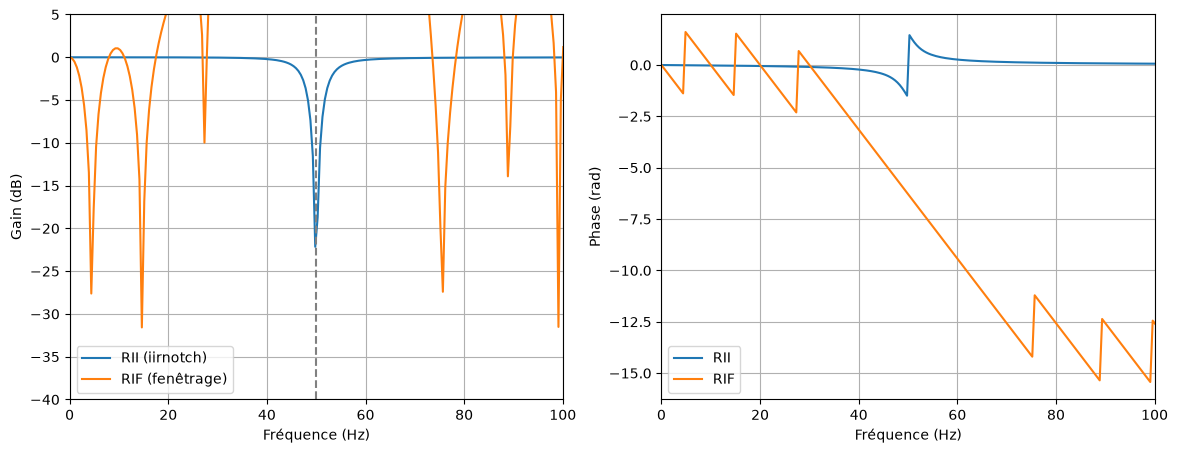

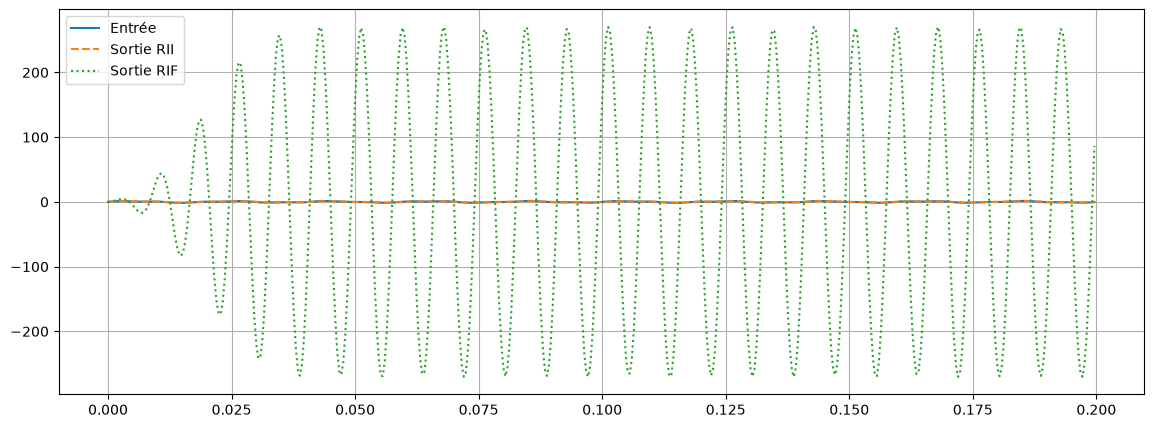

In [7]:
fs = 1000
f0 = 50
Q = 10

# Filtre notch RII (iirnotch)
b_notch, a_notch = signal.iirnotch(f0, Q, fs)

# Filtre notch RIF (fenêtre de Hamming, longueur 101)
N_notch = 101
# Conception par échantillonnage fréquentiel simple
# On va construire un filtre RIF coupe-bande en utilisant la méthode du fenêtrage
# mais pour un notch, on peut utiliser la formule de la réponse impulsionnelle idéale
# d'un coupe-bande : h_ideal[n] = (sin(omega_c2 n) - sin(omega_c1 n))/(pi n)
# avec omega_c1 = 2*pi*(f0 - BW/2)/fs, omega_c2 = 2*pi*(f0 + BW/2)/fs
BW = 10  # Hz
wc1 = 2*np.pi*(f0 - BW/2)/fs
wc2 = 2*np.pi*(f0 + BW/2)/fs
n = np.arange(-(N_notch-1)//2, (N_notch-1)//2 + 1)
h_ideal = np.zeros_like(n, dtype=float)
for i, n_i in enumerate(n):
    if n_i == 0:
        h_ideal[i] = (wc2 - wc1) / np.pi
    else:
        h_ideal[i] = (np.sin(wc2 * n_i) - np.sin(wc1 * n_i)) / (np.pi * n_i)
# Fenêtre de Hamming
window = np.hamming(N_notch)
h_fir = h_ideal * window
h_fir = h_fir / np.sum(h_fir)  # normalisation

# Réponses
w, H_notch_iir = signal.freqz(b_notch, a_notch, worN=1024)
w, H_notch_fir = signal.freqz(h_fir, 1, worN=1024)
freqs = w * fs / (2*np.pi)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(freqs, 20*np.log10(np.abs(H_notch_iir)), label='RII (iirnotch)')
plt.plot(freqs, 20*np.log10(np.abs(H_notch_fir)), label='RIF (fenêtrage)')
plt.axvline(f0, color='gray', linestyle='--')
plt.xlim(0, 100)
plt.ylim(-40, 5)
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Gain (dB)')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(freqs, np.unwrap(np.angle(H_notch_iir)), label='RII')
plt.plot(freqs, np.unwrap(np.angle(H_notch_fir)), label='RIF')
plt.xlim(0, 100)
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Phase (rad)')
plt.legend()
plt.grid()
plt.show()

# Test sur signal
t = np.linspace(0, 0.2, 500, endpoint=False)
x = np.sin(2*np.pi*50*t) + 0.5*np.sin(2*np.pi*120*t)
y_iir = signal.lfilter(b_notch, a_notch, x)
y_fir = signal.lfilter(h_fir, 1, x)

plt.figure(figsize=(14, 5))
plt.plot(t, x, label='Entrée')
plt.plot(t, y_iir, '--', label='Sortie RII')
plt.plot(t, y_fir, ':', label='Sortie RIF')
plt.legend()
plt.grid()
plt.show()

# 4. Exercices – Semaine 10

## Exercice 1 – Implémentation d'un filtre RIF en structure symétrique

Pour un filtre RIF à phase linéaire de longueur impaire, les coefficients sont symétriques. Écrire une fonction `fir_linear_phase(x, b)` qui exploite la symétrie pour réduire le nombre de multiplications de moitié. Tester avec un filtre de longueur 31.

**Code** :

Longueur du filtre : 31
Multiplications classiques : 31
Multiplications symétriques : 16
Résultats identiques : True


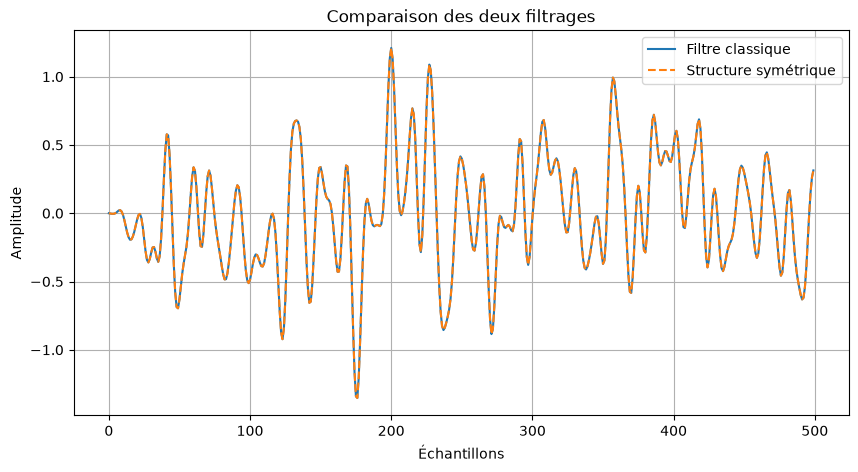

In [29]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Fonction RIF à phase linéaire en structure symétrique
def fir_linear_phase(x, b):

    N = len(b)
    L = len(x)

    # Vérifier que la longueur est impaire
    if N % 2 == 0:
        raise ValueError("La longueur du filtre doit être impaire")

    # Vérifier la symétrie des coefficients
    if not np.allclose(b, b[::-1]):
        raise ValueError("Les coefficients ne sont pas symétriques")

    M = N // 2

    # Ajouter des zéros au début du signal
    x_pad = np.pad(x, (N-1, 0))

    # Initialiser la sortie
    y = np.zeros(L)

    # Calcul en exploitant la symétrie
    for n in range(L):

        s = 0

        for k in range(M):
            s += b[k] * (
                x_pad[N-1+n-k] +
                x_pad[N-1+n-(N-1-k)]
            )

        # Coefficient central
        s += b[M] * x_pad[N-1+n-M]

        y[n] = s

    return y


# Test avec un filtre de longueur 31
N = 31
b = signal.firwin(N, 0.2)

# Signal d'entrée
x = np.random.randn(500)

# Filtrage avec notre fonction
y_sym = fir_linear_phase(x, b)

# Filtrage classique pour comparaison
y_classique = signal.lfilter(b, 1, x)

# Vérification
print("Longueur du filtre :", N)
print("Multiplications classiques :", N)
print("Multiplications symétriques :", (N+1)//2)

print("Résultats identiques :",
      np.allclose(y_sym, y_classique))

# Affichage
plt.figure(figsize=(10, 5))
plt.plot(y_classique, label="Filtre classique")
plt.plot(y_sym, '--', label="Structure symétrique")
plt.title("Comparaison des deux filtrages")
plt.xlabel("Échantillons")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()


## Exercice 2 – Filtre RII en cascade vs directe

1. Concevoir un filtre RII elliptique passe-bas avec les spécifications suivantes :
   - Fréquence de coupure 200 Hz, fs=1000 Hz.
   - Atténuation de 60 dB dans la bande stop à partir de 250 Hz.
   - Ondulation en bande passante : 0.5 dB.
2. Obtenir la forme en cascade (sos) et la forme directe.
3. Comparer les réponses en gain et en phase des deux formes.
4. Quantifier les coefficients sur 12 bits et observer l'impact sur la stabilité pour les deux structures.

**Code** :

Ordre du filtre : 7
Coefficients b : [0.01368641 0.02455482 0.04986251 0.06054864 0.06054864 0.04986251
 0.02455482 0.01368641]
Coefficients a : [ 1.         -2.92776442  5.4197203  -6.45075451  5.48023328 -3.2025049
  1.21746154 -0.23908653]
Coefficients SOS :
 [[ 0.01368641  0.01285982  0.01368641  1.         -0.60497279  0.        ]
 [ 1.          1.          0.          1.         -1.01025142  0.53333365]
 [ 1.          0.0667737   1.          1.         -0.72177203  0.78593591]
 [ 1.         -0.21227662  1.          1.         -0.59076817  0.94282945]]


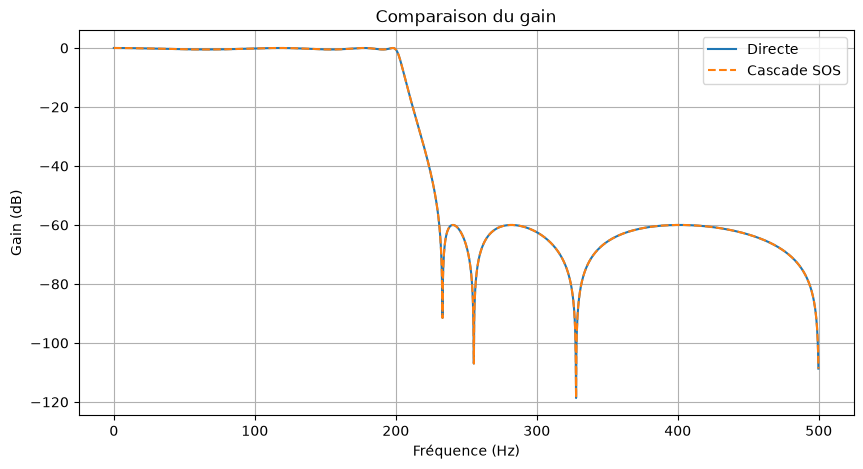

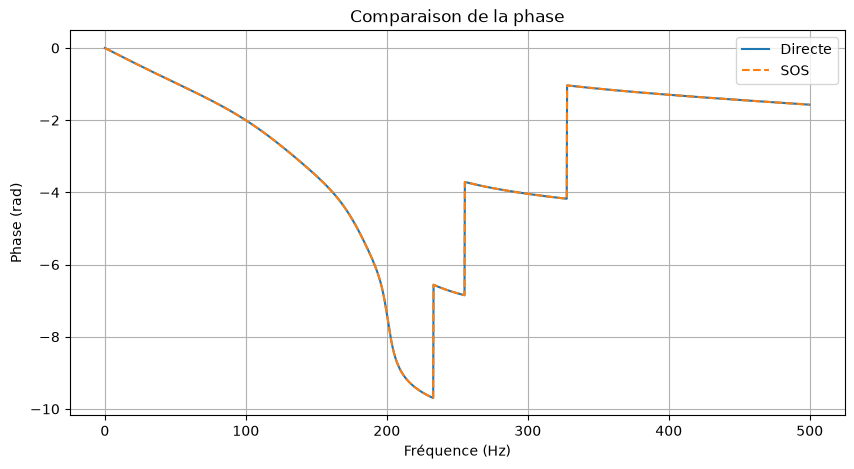


--- STABILITE ---
Directe : True
SOS : True
Rayon maximal direct : 0.970143139037037
Rayon maximal SOS : 0.9709940535038303


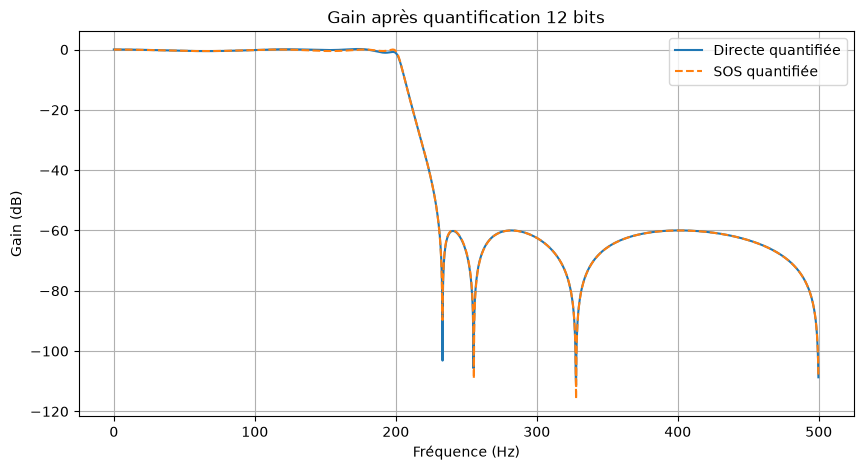

In [31]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# =====================================
# 1. CONCEPTION DU FILTRE ELLIPTIQUE
# =====================================

fs = 1000
fc = 200
f_stop = 250
rp = 0.5
rs = 60

wp = fc / (fs/2)
ws = f_stop / (fs/2)

# Calcul de l'ordre
ordre, wn = signal.ellipord(wp, ws, rp, rs)

# Forme directe
b, a = signal.ellip(ordre, rp, rs, wn, btype='low')

# Forme cascade
sos = signal.ellip(ordre, rp, rs, wn,
                   btype='low', output='sos')

print("Ordre du filtre :", ordre)
print("Coefficients b :", b)
print("Coefficients a :", a)
print("Coefficients SOS :\n", sos)


# =====================================
# 2. COMPARAISON GAIN ET PHASE
# =====================================

f, h_direct = signal.freqz(b, a, worN=2048, fs=fs)
f, h_sos = signal.sosfreqz(sos, worN=2048, fs=fs)

plt.figure(figsize=(10,5))
plt.plot(f, 20*np.log10(np.maximum(abs(h_direct), 1e-12)),
         label="Directe")
plt.plot(f, 20*np.log10(np.maximum(abs(h_sos), 1e-12)),
         '--', label="Cascade SOS")
plt.title("Comparaison du gain")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Gain (dB)")
plt.grid()
plt.legend()
plt.show()

plt.figure(figsize=(10,5))
plt.plot(f, np.unwrap(np.angle(h_direct)), label="Directe")
plt.plot(f, np.unwrap(np.angle(h_sos)), '--', label="SOS")
plt.title("Comparaison de la phase")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Phase (rad)")
plt.grid()
plt.legend()
plt.show()


# =====================================
# 3. QUANTIFICATION SUR 12 BITS
# =====================================

def quantifier(c, bits=12):
    qmax = 2**(bits-1)-1
    delta = np.max(np.abs(c))/qmax

    if delta == 0:
        return c.copy()

    return np.round(c/delta)*delta


# Quantification directe
bq = quantifier(b)
aq = quantifier(a)

# Normalisation par a0
bq = bq/aq[0]
aq = aq/aq[0]

# Quantification SOS
sosq = sos.copy()

for i in range(len(sos)):
    # Quantifier les coefficients a1, a2 et b0, b1, b2
    sosq[i, :3] = quantifier(sos[i, :3])
    sosq[i, 4:] = quantifier(sos[i, 4:])

    # Garder a0 = 1
    sosq[i, 3] = 1


# =====================================
# 4. STABILITE
# =====================================

p_direct = np.roots(aq)

p_sos = []

for section in sosq:
    p_sos.extend(np.roots(section[3:]))

print("\n--- STABILITE ---")

print("Directe :", np.all(np.abs(p_direct) < 1))
print("SOS :", np.all(np.abs(p_sos) < 1))

print("Rayon maximal direct :",
      np.max(np.abs(p_direct)))

print("Rayon maximal SOS :",
      np.max(np.abs(p_sos)))


# =====================================
# 5. REPONSE APRES QUANTIFICATION
# =====================================

f, h_direct_q = signal.freqz(bq, aq, worN=2048, fs=fs)

f, h_sos_q = signal.sosfreqz(sosq, worN=2048, fs=fs)

plt.figure(figsize=(10,5))

plt.plot(f, 20*np.log10(np.maximum(abs(h_direct_q), 1e-12)),
         label="Directe quantifiée")

plt.plot(f, 20*np.log10(np.maximum(abs(h_sos_q), 1e-12)),
         '--', label="SOS quantifiée")

plt.title("Gain après quantification 12 bits")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Gain (dB)")
plt.grid()
plt.legend()
plt.show()


## Exercice 3 – Analyse du retard de groupe d'un filtre RIF et RII

1. Concevoir un filtre RIF passe-bas de type window (Hamming) avec fc=150 Hz, fs=1000 Hz, ordre 50.
2. Concevoir un filtre RII Butterworth d'ordre 6 avec les mêmes spécifications.
3. Tracer le retard de groupe des deux filtres sur la bande passante.
4. Commenter la distorsion de phase introduite par chaque filtre.

**Code** :

C:\Users\RAWAA\AppData\Local\Temp\ipykernel_6712\4108583923.py:49: UserWarning: The filter's denominator is extremely small at frequencies [3.135], around which a singularity may be present
  w_iir, gd_iir = signal.group_delay(


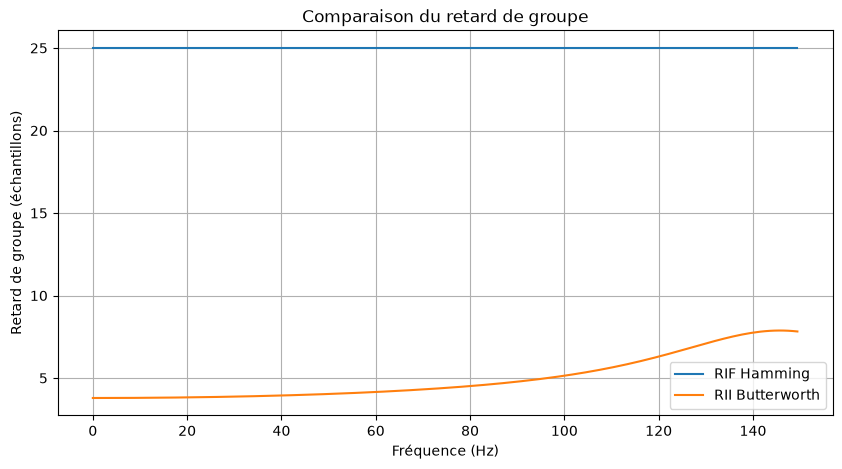

Retard de groupe RIF moyen : 25.0
Retard de groupe RII moyen : 4.994263815163892
Retard théorique RIF : 25.0


In [32]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# =====================================
# 1. PARAMETRES
# =====================================

fs = 1000
fc = 150

# =====================================
# 2. CONCEPTION DU FILTRE RIF
# =====================================

ordre_fir = 50

b_fir = signal.firwin(
    ordre_fir + 1,
    fc,
    window='hamming',
    fs=fs
)

a_fir = [1]

# =====================================
# 3. CONCEPTION DU FILTRE RII BUTTERWORTH
# =====================================

ordre_iir = 6

b_iir, a_iir = signal.butter(
    ordre_iir,
    fc,
    btype='low',
    fs=fs
)

# =====================================
# 4. CALCUL DU RETARD DE GROUPE
# =====================================

w_fir, gd_fir = signal.group_delay(
    (b_fir, a_fir),
    fs=fs
)

w_iir, gd_iir = signal.group_delay(
    (b_iir, a_iir),
    fs=fs
)

# =====================================
# 5. AFFICHAGE SUR LA BANDE PASSANTE
# =====================================

plt.figure(figsize=(10, 5))

# Bande passante : 0 à 150 Hz
plt.plot(w_fir[w_fir <= fc],
         gd_fir[w_fir <= fc],
         label='RIF Hamming')

plt.plot(w_iir[w_iir <= fc],
         gd_iir[w_iir <= fc],
         label='RII Butterworth')

plt.title("Comparaison du retard de groupe")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Retard de groupe (échantillons)")

plt.grid()
plt.legend()
plt.show()

# =====================================
# 6. VALEURS DU RETARD DE GROUPE
# =====================================

print("Retard de groupe RIF moyen :",
      np.mean(gd_fir[w_fir <= fc]))

print("Retard de groupe RII moyen :",
      np.mean(gd_iir[w_iir <= fc]))

print("Retard théorique RIF :",
      ordre_fir / 2)


## Exercice 4 – Effet du nombre de bits sur la réponse d'un filtre RII

Pour un filtre RII passe-bande (Butterworth ordre 4, bande 100-200 Hz, fs=1000 Hz) :
1. Quantifier les coefficients avec différentes résolutions (8, 10, 12, 16 bits).
2. Pour chaque résolution, tracer la réponse en gain et repérer les dégradations.
3. Observer le déplacement des pôles et déterminer la résolution minimale pour garantir la stabilité.

**Code** :

Coefficients b : [ 0.00482434  0.         -0.01929737  0.          0.02894606  0.
 -0.01929737  0.          0.00482434]
Coefficients a : [  1.          -3.93657553   8.2603943  -11.2174259   10.78363101
  -7.39144283   3.57650493  -1.11504665   0.18737949]


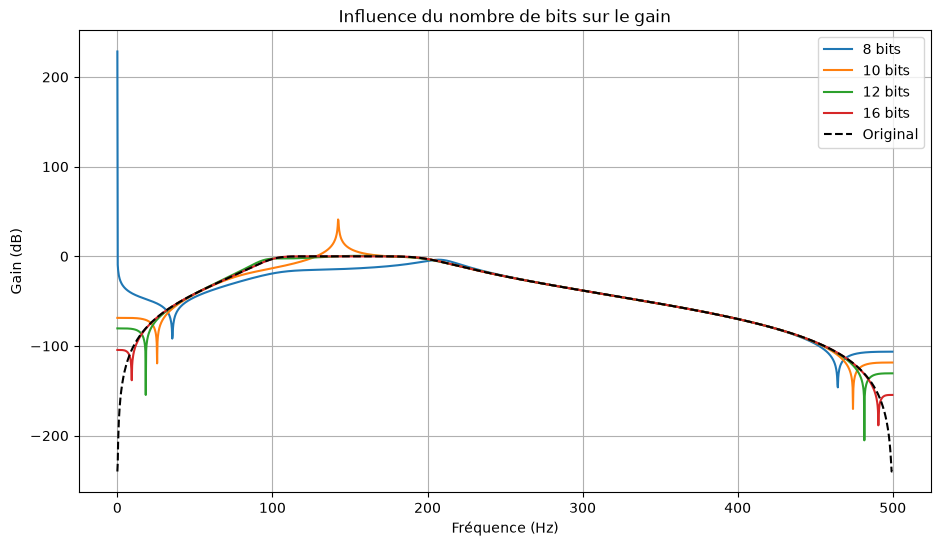


===== STABILITE =====

Résolution : 8 bits
Rayon maximal : 1.166878572693912
Stable : False

Résolution : 10 bits
Rayon maximal : 1.0007713852287883
Stable : False

Résolution : 12 bits
Rayon maximal : 0.9368866603757122
Stable : True

Résolution : 16 bits
Rayon maximal : 0.9163822400471386
Stable : True


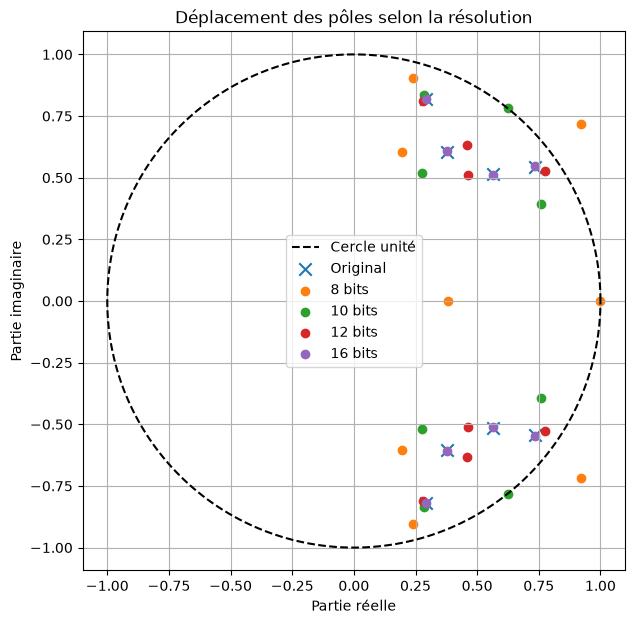

In [33]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# =========================================
# 1. PARAMETRES
# =========================================

fs = 1000
f1 = 100
f2 = 200
ordre = 4

bits_list = [8, 10, 12, 16]

# =========================================
# 2. CONCEPTION DU FILTRE RII
# =========================================

b, a = signal.butter(
    ordre,
    [f1, f2],
    btype='bandpass',
    fs=fs
)

print("Coefficients b :", b)
print("Coefficients a :", a)

# =========================================
# 3. FONCTION DE QUANTIFICATION
# =========================================

def quantifier(c, bits):

    qmax = 2**(bits-1)-1

    max_val = np.max(np.abs(c))

    delta = max_val / qmax

    cq = np.round(c / delta) * delta

    return cq


# =========================================
# 4. REPONSE EN GAIN
# =========================================

plt.figure(figsize=(11, 6))

for bits in bits_list:

    bq = quantifier(b, bits)
    aq = quantifier(a, bits)

    # Normalisation par a0
    bq = bq / aq[0]
    aq = aq / aq[0]

    f, h = signal.freqz(bq, aq, worN=2048, fs=fs)

    gain = 20 * np.log10(np.maximum(np.abs(h), 1e-12))

    plt.plot(f, gain, label=f'{bits} bits')


# Réponse originale
f, h = signal.freqz(b, a, worN=2048, fs=fs)

plt.plot(f, 20*np.log10(np.maximum(np.abs(h), 1e-12)),
         'k--', label='Original')

plt.title("Influence du nombre de bits sur le gain")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Gain (dB)")
plt.grid()
plt.legend()
plt.show()


# =========================================
# 5. ETUDE DES POLES ET STABILITE
# =========================================

plt.figure(figsize=(7, 7))

# Cercle unité
theta = np.linspace(0, 2*np.pi, 500)

plt.plot(np.cos(theta), np.sin(theta),
         'k--', label='Cercle unité')

# Pôles originaux
p_original = np.roots(a)

plt.scatter(np.real(p_original),
            np.imag(p_original),
            marker='x', s=80, label='Original')

print("\n===== STABILITE =====")

for bits in bits_list:

    bq = quantifier(b, bits)
    aq = quantifier(a, bits)

    bq = bq / aq[0]
    aq = aq / aq[0]

    poles = np.roots(aq)

    rayon = np.max(np.abs(poles))

    stable = np.all(np.abs(poles) < 1)

    print(f"\nRésolution : {bits} bits")
    print("Rayon maximal :", rayon)
    print("Stable :", stable)

    plt.scatter(np.real(poles),
                np.imag(poles),
                label=f'{bits} bits')

plt.title("Déplacement des pôles selon la résolution")
plt.xlabel("Partie réelle")
plt.ylabel("Partie imaginaire")
plt.axis('equal')
plt.grid()
plt.legend()
plt.show()


## Exercice 5 – Mise en œuvre d'un filtre adaptatif simple (LMS) – Introduction

Un filtre adaptatif permet d'ajuster ses coefficients pour minimiser une erreur. Implémenter un filtre RIF adaptatif utilisant l'algorithme LMS (Least Mean Squares) pour annuler un écho. On donne un signal désiré $d[n]$ et un signal d'entrée $x[n]$ corrélé avec l'écho.

1. Générer un signal $x[n]$ aléatoire.
2. Créer un signal écho : $y[n] = 0.8 x[n-10] + bruit$.
3. Utiliser un filtre RIF de longueur 20 pour estimer la réponse de l'écho.
4. Appliquer l'algorithme LMS (pas = 0.01) pour mettre à jour les coefficients.
5. Afficher l'erreur en fonction des itérations et les coefficients convergés.

**Code** :

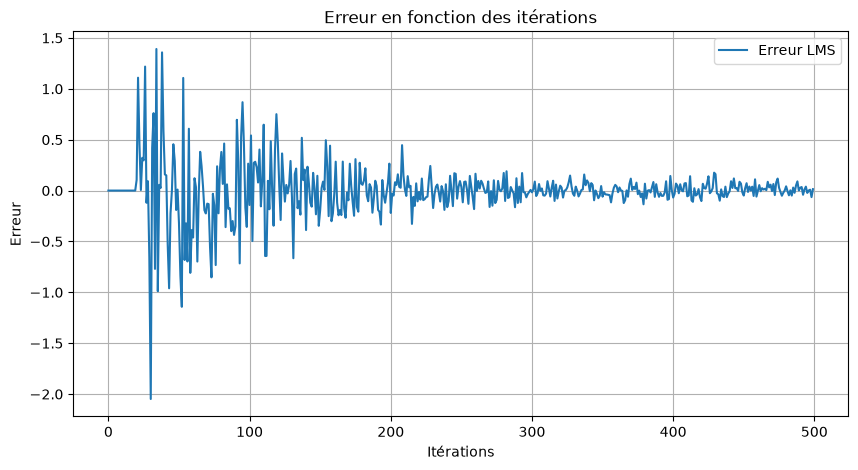

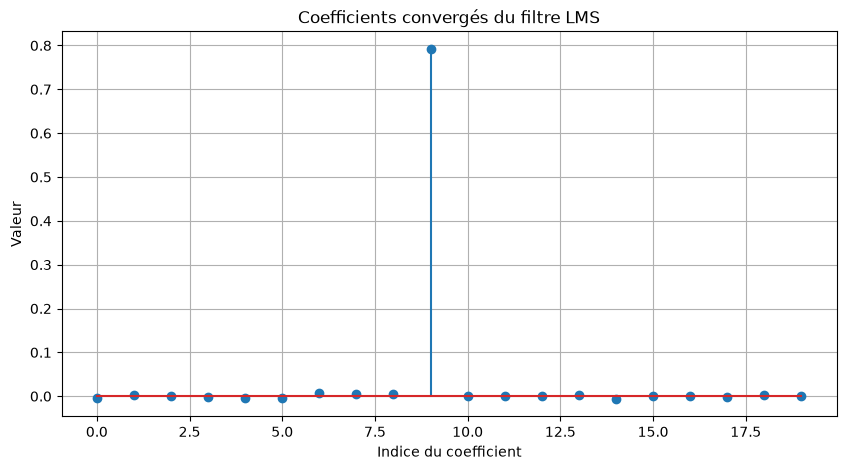

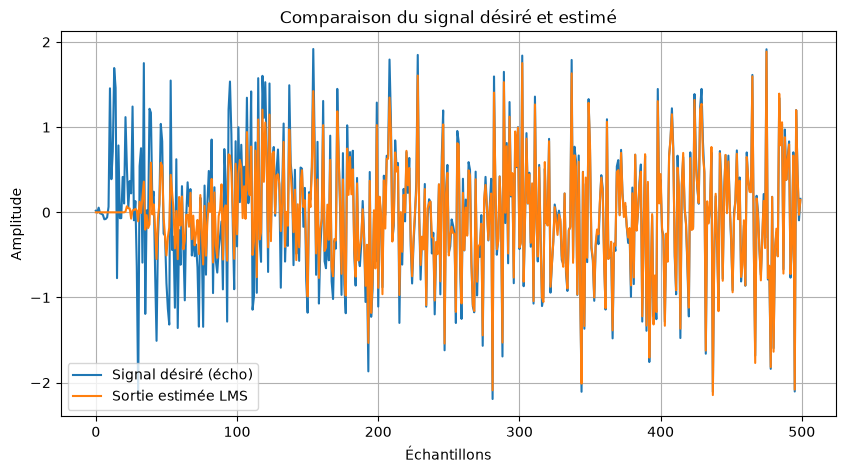

Coefficients convergés :
[-4.09508257e-03  2.55672343e-03  1.19733716e-03 -1.13003655e-03
 -4.83019754e-03 -3.83650196e-03  6.70010567e-03  3.91644678e-03
  4.41834171e-03  7.91973167e-01  1.26723241e-03 -1.30914300e-04
  7.32731092e-04  3.58998511e-03 -6.34438440e-03 -6.24955610e-04
  7.33117172e-04 -9.85655753e-04  3.69274049e-03  1.31993668e-03]

Erreur quadratique moyenne :
0.0775195914692262


In [35]:

import numpy as np
import matplotlib.pyplot as plt

# =========================================
# 1. ALGORITHME LMS
# =========================================

def lms_filter(x, d, M, mu):

    N = len(x)

    # Initialisation des coefficients
    w = np.zeros(M)

    # Initialisation des signaux
    y = np.zeros(N)
    e = np.zeros(N)

    for n in range(M, N):

        # Vecteur d'entrée
        x_n = x[n-M:n][::-1]

        # Sortie du filtre
        y[n] = np.dot(w, x_n)

        # Calcul de l'erreur
        e[n] = d[n] - y[n]

        # Mise à jour des coefficients
        w = w + mu * e[n] * x_n

    return y, e, w


# =========================================
# 2. GENERATION DU SIGNAL
# =========================================

N = 500
M = 20
mu = 0.01

# Signal aléatoire
np.random.seed(0)
x = np.random.randn(N)

# Création du retard de 10 échantillons
x_retard = np.concatenate((np.zeros(10), x[:-10]))

# Bruit
bruit = 0.05 * np.random.randn(N)

# Signal écho (signal désiré)
d = 0.8 * x_retard + bruit


# =========================================
# 3. APPLICATION DU FILTRE LMS
# =========================================

y, e, w = lms_filter(x, d, M, mu)


# =========================================
# 4. AFFICHAGE DE L'ERREUR
# =========================================

plt.figure(figsize=(10,5))

plt.plot(e, label="Erreur LMS")
plt.title("Erreur en fonction des itérations")
plt.xlabel("Itérations")
plt.ylabel("Erreur")
plt.grid()
plt.legend()
plt.show()


# =========================================
# 5. COEFFICIENTS CONVERGES
# =========================================

plt.figure(figsize=(10,5))

plt.stem(w)

plt.title("Coefficients convergés du filtre LMS")
plt.xlabel("Indice du coefficient")
plt.ylabel("Valeur")
plt.grid()
plt.show()


# =========================================
# 6. COMPARAISON DES SIGNAUX
# =========================================

plt.figure(figsize=(10,5))

plt.plot(d, label="Signal désiré (écho)")
plt.plot(y, label="Sortie estimée LMS")

plt.title("Comparaison du signal désiré et estimé")
plt.xlabel("Échantillons")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()


# =========================================
# 7. RESULTATS
# =========================================

print("Coefficients convergés :")
print(w)

print("\nErreur quadratique moyenne :")
print(np.mean(e[M:]**2))


# 5. Livrable Semaine 10

- Remplir les cellules de code avec vos solutions.
- Répondre aux questions théoriques dans les cellules markdown.
- Inclure des commentaires explicatifs.
- Rendre le notebook complet (cellules exécutées).

**Date de rendu** : à définir par l'enseignant.

---